# Seasonal LST, UTFVI and CA-ANN land change in Cumilla, Bangladesh

Companion workflow for Kafy et al. (2021), *Sustainable Cities and Society* 64, 102542.

Steps:
1. Load seasonal Landsat composites (1999, 2009, 2019) made by `download.py`.
2. Classify land cover with a Random Forest trained on ESA WorldCover 2020 labels.
3. Validate a CA-ANN land change model (1999 to 2009 predicts 2019), then project 2029 and 2039.
4. Model summer and winter land surface temperature (LST) from land cover with an ANN.
5. Compute the Urban Thermal Field Variance Index (UTFVI) for observed and projected years.

Runtime: about 3 minutes on a laptop.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import ListedColormap

from landsat_climate import lulc as L
from landsat_climate.caann import CAANN, kappa, transition_matrix
from landsat_climate.lstmodel import fit_lst_model, predict_lst
from landsat_climate.thermal import UTFVI_CLASSES, classify_utfvi, utfvi

DATA, OUT, FIG = Path("data"), Path("outputs"), Path("figures")
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
comp = xr.open_dataset(DATA / "composites.nc")
dem = xr.open_dataarray(DATA / "dem.nc").values
labels = L.worldcover_labels(xr.open_dataarray(DATA / "worldcover2020.nc").values)
scenes = pd.read_csv(DATA / "scenes.csv")
print(dict(comp.sizes)); scenes.groupby(["year", "season"]).scene.count().rename("scenes")

{'year': 3, 'season': 2, 'y': 247, 'x': 247}


year  season
1999  summer    4
      winter    8
2009  summer    4
      winter    8
2019  summer    3
      winter    8
Name: scenes, dtype: int64

## 1. Land cover classification

In [2]:
model, report = L.train_classifier(L.features(comp, 2019), labels)
print(f"Spatial holdout (2019 vs WorldCover 2020): overall accuracy {report['overall_accuracy']:.3f}, "
      f"kappa {report['kappa']:.3f}, n = {report['n_test']:,} pixels")
pd.DataFrame(report["confusion"], index=L.CLASSES.values(), columns=L.CLASSES.values())

Spatial holdout (2019 vs WorldCover 2020): overall accuracy 0.797, kappa 0.689, n = 16,560 pixels


,Water,Built-up,Vegetation,Cropland and bare
Water,209,36,17,66
Built-up,17,2663,322,136
Vegetation,30,474,5705,1004
Cropland and bare,89,228,939,4625


In [3]:
maps = {y: L.classify(model, L.features(comp, y)) for y in (1999, 2009, 2019)}
pd.DataFrame({y: L.class_shares(m) for y, m in maps.items()}).round(1)

,1999,2009,2019
Water,2.0,2.2,2.4
Built-up,10.8,16.7,21.7
Vegetation,38.9,38.0,41.5
Cropland and bare,48.3,43.2,34.4


## 2. CA-ANN land change model

**Validation.** Fit on 1999 to 2009, simulate 2019 from 2009, compare with the classified 2019 map. A useful model must beat the "no change" baseline (2009 map used as the 2019 forecast).

In [4]:
ca_val = CAANN().fit(maps[1999], maps[2009], dem)
sim2019 = ca_val.step(maps[2009], dem, transition_matrix(maps[1999], maps[2009]))
val = pd.DataFrame(
    {"CA-ANN (simulated 2019)": kappa(sim2019, maps[2019]),
     "No change (2009 as 2019)": kappa(maps[2009], maps[2019])},
    index=["agreement", "kappa"]).T.round(3)
val

,agreement,kappa
CA-ANN (simulated 2019),0.717,0.572
No change (2009 as 2019),0.695,0.535


**Projection.** Fit on 2009 to 2019, then step forward 10 years twice.

In [5]:
ca = CAANN().fit(maps[2009], maps[2019], dem)
P = transition_matrix(maps[2009], maps[2019])
maps[2029] = ca.step(maps[2019], dem, P)
maps[2039] = ca.step(maps[2029], dem, P)
shares = pd.DataFrame({y: L.class_shares(m) for y, m in maps.items()}).round(1)
shares.to_csv(OUT / "lulc_shares_percent.csv")
shares

,1999,2009,2019,2029,2039
Water,2.0,2.2,2.4,2.6,2.8
Built-up,10.8,16.7,21.7,25.6,28.4
Vegetation,38.9,38.0,41.5,42.5,42.5
Cropland and bare,48.3,43.2,34.4,29.3,26.3


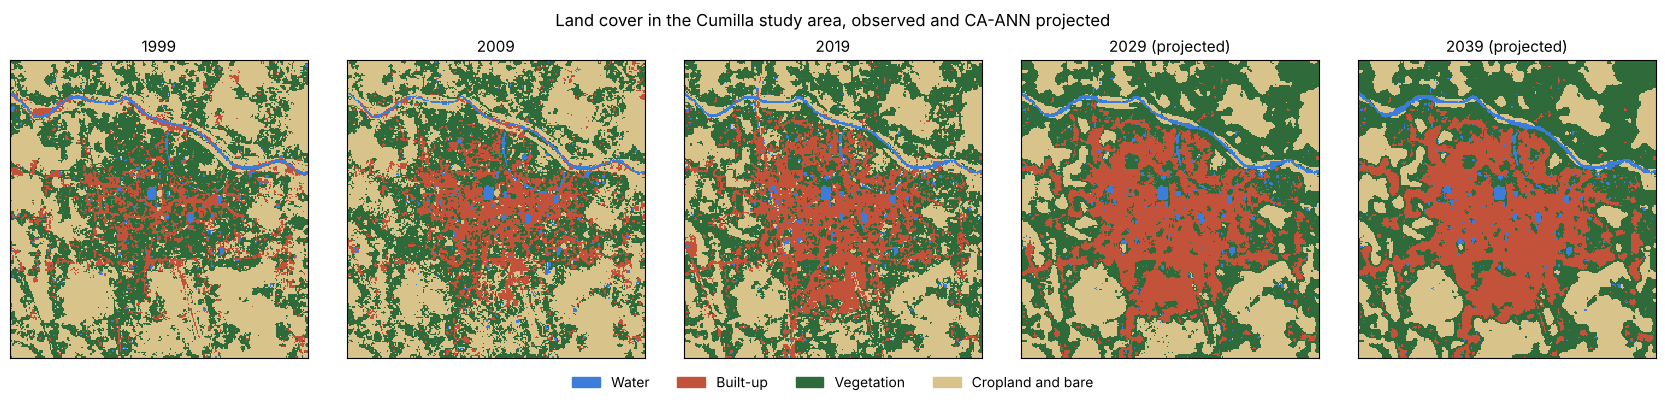

In [6]:
cmap = ListedColormap([L.COLORS[c] for c in L.CLASSES])
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9))
for ax, (y, m) in zip(axes, sorted(maps.items())):
    ax.imshow(np.where(m > 0, m, np.nan), cmap=cmap, vmin=0.5, vmax=4.5, interpolation="nearest")
    ax.set_title(f"{y}" + (" (projected)" if y > 2019 else ""), fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Rectangle((0, 0), 1, 1, color=L.COLORS[c]) for c in L.CLASSES]
fig.legend(handles, L.CLASSES.values(), loc="lower center", ncol=4, frameon=False)
fig.suptitle("Land cover in the Cumilla study area, observed and CA-ANN projected", y=1.0)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG / "fig1_lulc.png", dpi=200, bbox_inches="tight")

## 3. Seasonal land surface temperature

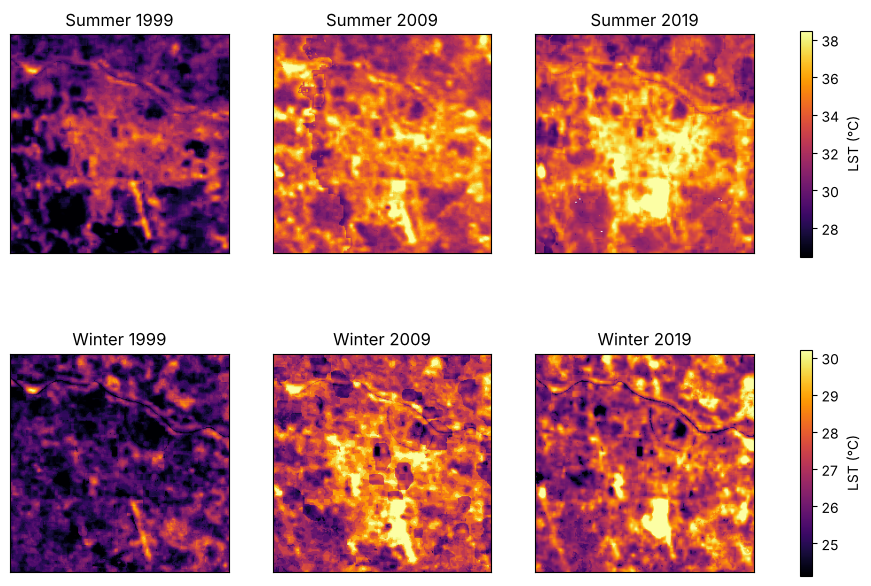

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
for i, season in enumerate(("summer", "winter")):
    vals = comp.lst.sel(season=season)
    lo, hi = np.nanpercentile(vals, [2, 98])
    for j, y in enumerate((1999, 2009, 2019)):
        im = axes[i, j].imshow(vals.sel(year=y), cmap="inferno", vmin=lo, vmax=hi)
        axes[i, j].set_title(f"{season.title()} {y}"); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    fig.colorbar(im, ax=axes[i, :], shrink=0.85, label="LST (°C)")
fig.savefig(FIG / "fig2_lst.png", dpi=200, bbox_inches="tight")

In [8]:
rows = []
for season in ("summer", "winter"):
    for y in (1999, 2009, 2019):
        lst = comp.lst.sel(year=y, season=season).values
        rows.append({"season": season, "year": y, **{n: np.nanmean(lst[maps[y] == c]) for c, n in L.CLASSES.items()},
                     "mean": np.nanmean(lst)})
lst_by_class = pd.DataFrame(rows).round(2)
lst_by_class["built-up minus vegetation"] = (lst_by_class["Built-up"] - lst_by_class["Vegetation"]).round(2)
lst_by_class.to_csv(OUT / "lst_by_class_c.csv", index=False)
lst_by_class

,season,year,Water,Built-up,Vegetation,Cropland and bare,mean,built-up minus vegetation
0,summer,1999,30.330000,32.459999,30.500000,28.629999,29.809999,1.96
1,summer,2009,33.900002,35.840000,33.980000,33.139999,33.919998,1.86
2,summer,2019,34.169998,37.029999,33.950001,32.599998,34.160000,3.08
3,winter,1999,24.540001,25.760000,25.020000,25.700001,25.420000,0.74
4,winter,2009,26.980000,28.680000,27.379999,27.250000,27.530001,1.30
5,winter,2019,26.100000,28.000000,26.940001,27.660000,27.400000,1.06


**ANN model of LST from land cover**, trained on 2019 and scored with 5-fold spatial block cross-validation. It is then applied to the projected 2029 and 2039 land cover. Climate is held at 2019 conditions, so projections show the effect of land cover change alone.

In [9]:
proj, scores = {}, {}
for season in ("summer", "winter"):
    lst19 = comp.lst.sel(year=2019, season=season).values
    mdl, scores[season] = fit_lst_model(maps[2019], dem, lst19)
    proj[season] = {2019: lst19, 2029: predict_lst(mdl, maps[2029], dem), 2039: predict_lst(mdl, maps[2039], dem)}
pd.DataFrame(scores).T.round(3)

,r2,rmse
summer,0.695,1.290
winter,0.296,1.102


## 4. Urban Thermal Field Variance Index

In [10]:
rows = []
for season in ("summer", "winter"):
    series = {y: comp.lst.sel(year=y, season=season).values for y in (1999, 2009)} | proj[season]
    for y, lst in sorted(series.items()):
        cls = classify_utfvi(utfvi(lst))
        rows.append({"season": season, "year": y, "source": "projected" if y > 2019 else "observed",
                     **{k: 100 * np.mean(cls == k) for k in UTFVI_CLASSES},
                     "area above 33 °C (%)": 100 * np.nanmean(lst > 33)})
ut = pd.DataFrame(rows).round(1)
ut.to_csv(OUT / "utfvi_class_shares_percent.csv", index=False)
ut

,season,year,source,None,Weak,Middle,Strong,Stronger,Strongest,area above 33 °C (%)
0,summer,1999,observed,51.5,21.6,17.7,7.5,1.5,0.2,8.1
1,summer,2009,observed,51.0,26.9,15.7,4.6,1.4,0.5,65.9
2,summer,2019,observed,54.0,20.4,15.4,7.1,1.6,1.4,64.5
3,summer,2029,projected,59.6,14.2,13.1,7.4,3.2,2.5,63.7
4,summer,2039,projected,60.7,12.2,11.8,7.1,4.3,3.9,66.2
5,winter,1999,observed,54.6,38.1,6.8,0.5,0.0,0.0,0.0
6,winter,2009,observed,54.5,34.1,9.3,1.8,0.2,0.1,0.2
7,winter,2019,observed,55.6,33.4,8.5,1.6,0.5,0.4,0.5
8,winter,2029,projected,61.7,28.1,7.4,2.1,0.7,0.0,0.2
9,winter,2039,projected,62.9,24.6,7.9,3.1,1.5,0.0,0.3


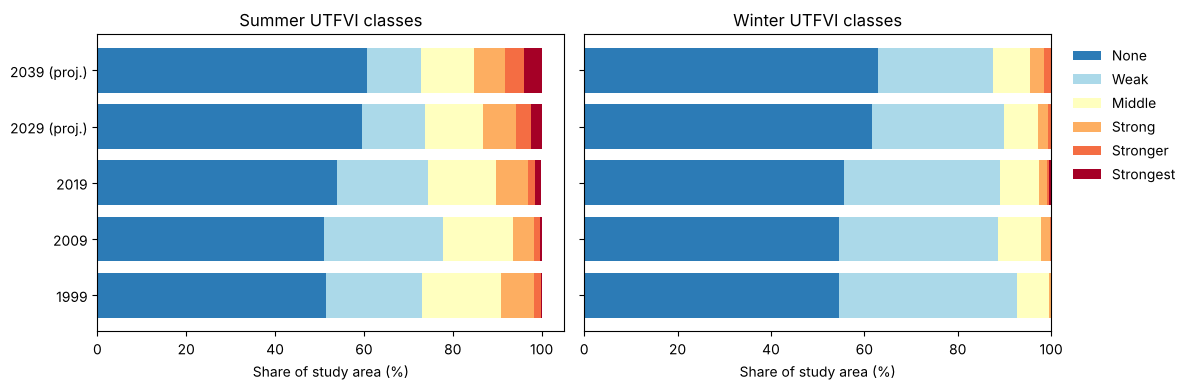

In [11]:
colors = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#f46d43", "#a50026"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, season in zip(axes, ("summer", "winter")):
    d = ut[ut.season == season].set_index("year")[list(UTFVI_CLASSES)]
    left = np.zeros(len(d))
    for k, col in zip(UTFVI_CLASSES, colors):
        ax.barh([str(y) + (" (proj.)" if y > 2019 else "") for y in d.index], d[k], left=left, color=col, label=k)
        left += d[k].values
    ax.set_title(f"{season.title()} UTFVI classes"); ax.set_xlabel("Share of study area (%)"); ax.invert_yaxis()
axes[1].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "fig3_utfvi.png", dpi=200, bbox_inches="tight")

In [12]:
summary = {
    "classification_overall_accuracy": round(report["overall_accuracy"], 3),
    "classification_kappa": round(report["kappa"], 3),
    "caann_validation": val.to_dict(orient="index"),
    "lst_model_cv": {k: {m: round(v, 3) for m, v in s.items()} for k, s in scores.items()},
    "builtup_percent": shares.loc["Built-up"].to_dict(),
    "vegetation_percent": shares.loc["Vegetation"].to_dict(),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
summary

{'classification_overall_accuracy': 0.797,
 'classification_kappa': 0.689,
 'caann_validation': {'CA-ANN (simulated 2019)': {'agreement': 0.717,
   'kappa': 0.572},
  'No change (2009 as 2019)': {'agreement': 0.695, 'kappa': 0.535}},
 'lst_model_cv': {'summer': {'r2': 0.695, 'rmse': 1.29},
  'winter': {'r2': 0.296, 'rmse': 1.102}},
 'builtup_percent': {1999: 10.8,
  2009: 16.7,
  2019: 21.7,
  2029: 25.6,
  2039: 28.4},
 'vegetation_percent': {1999: 38.9,
  2009: 38.0,
  2019: 41.5,
  2029: 42.5,
  2039: 42.5}}